Ссылка на clearml с логами обучения: [clearml](https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/f1e9824d5941477989f9641f42e62622/scalars?columns=selected&columns=type&columns=name&columns=tags&columns=status&columns=project.name&columns=users&columns=started&columns=last_update&columns=last_iteration&columns=parent.name&order=-last_update)

API ключи clearml намеренно удалены

In [1]:
!pip install -q clearml ultralytics

In [ ]:
import os
from clearml import Task
from ultralytics import YOLO
import logging

os.environ["CLEARML_WEB_HOST"] = "https://app.clear.ml"
os.environ["CLEARML_API_HOST"] = "https://api.clear.ml"
os.environ["CLEARML_FILES_HOST"] = "https://files.clear.ml"
os.environ["CLEARML_API_ACCESS_KEY"] = ""
os.environ["CLEARML_API_SECRET_KEY"] = ""

os.environ["CLEARML_NO_DEFAULT_CONFIG"] = "1"

ClearML Task: created new task id=f1e9824d5941477989f9641f42e62622
2026-10-23 13:50:42,891 - clearml.Repository Detection - WARNING - Jupyter Notebook auto-logging failed, could not access: /kaggle/working/__notebook_source__.ipynb
ClearML results page: https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/f1e9824d5941477989f9641f42e62622/output/log
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic_dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning:

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.



       2/50      6.29G      1.272      3.401    0.01282         12        640: 100% ━━━━━━━━━━━━ 16/16 4.1it/s 3.9s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.6it/s 1.1s0.3s
                   all        145         51      0.265      0.431      0.221      0.117

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      6.29G      1.413      2.136    0.01507         11        640: 100% ━━━━━━━━━━━━ 16/16 4.1it/s 3.9s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.7it/s 1.1s0.3s
                   all        145         51     0.0675     0.0392     0.0187    0.00709

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      6.29G      1.485      1.848    0.01485         13        640: 100% ━━━━━━━━━━━━ 16/16 3.9it/s 4.1s0.2s
                 Class     Images  Instances  

███████████████████████████████ 100% | 19.36/19.36 MB [00:00<00:00, 50.62MB/s]: 


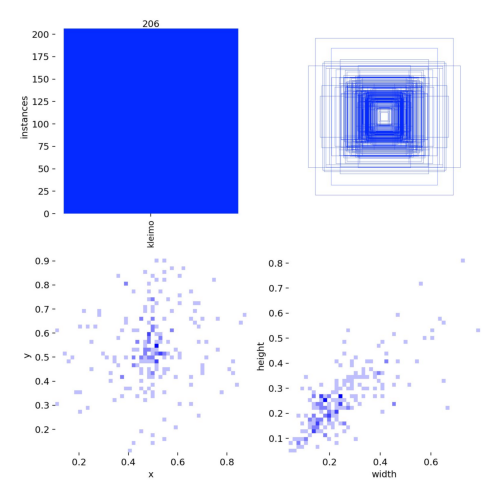

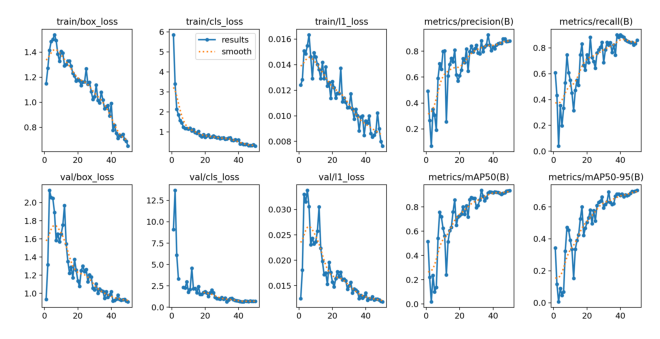

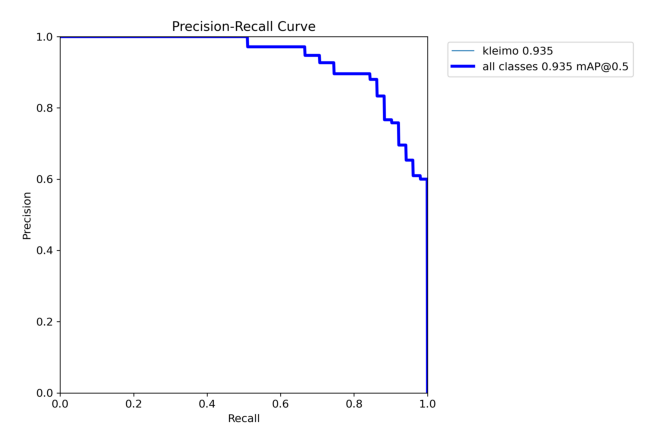

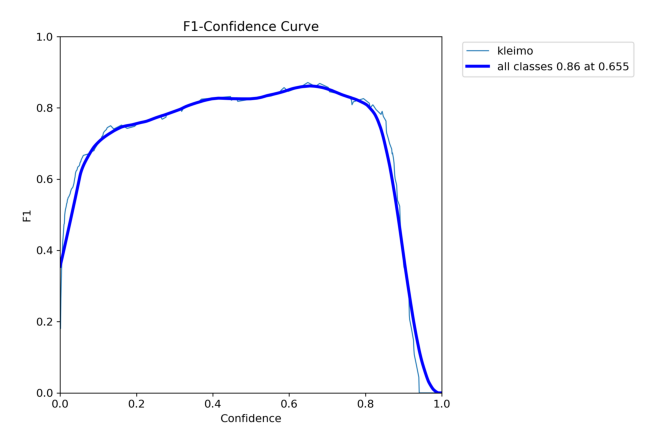

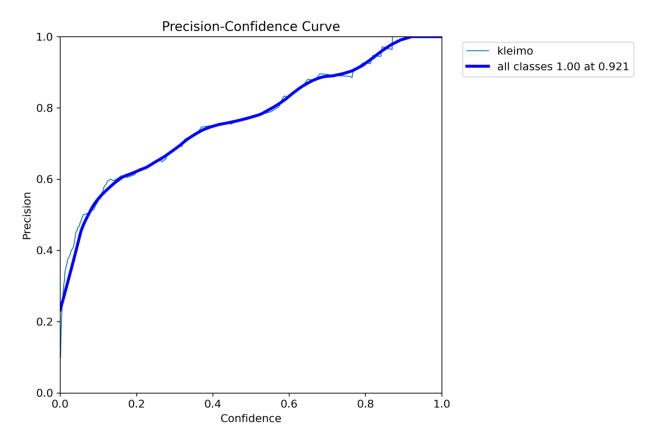

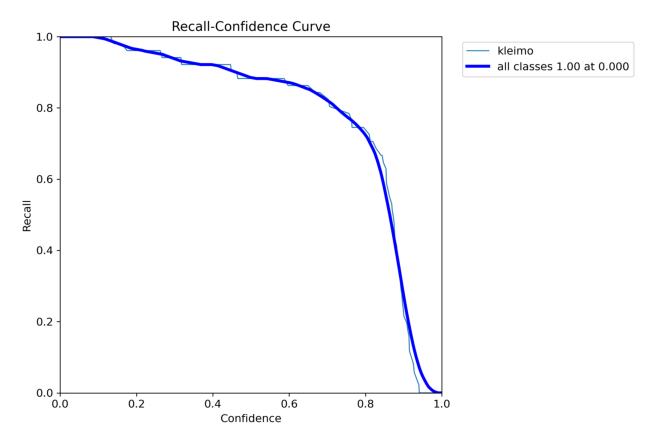

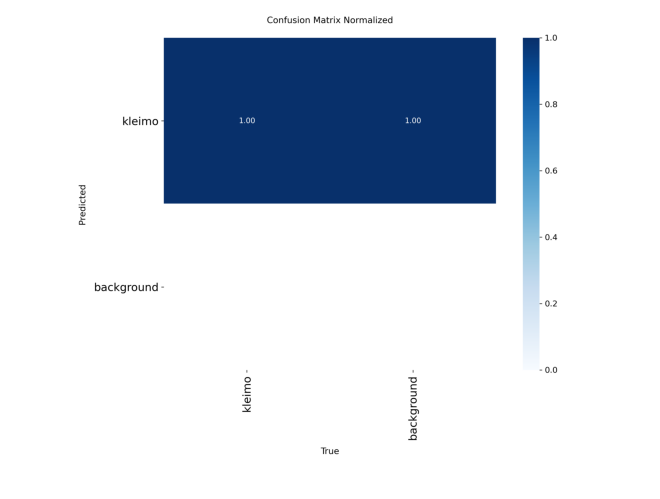

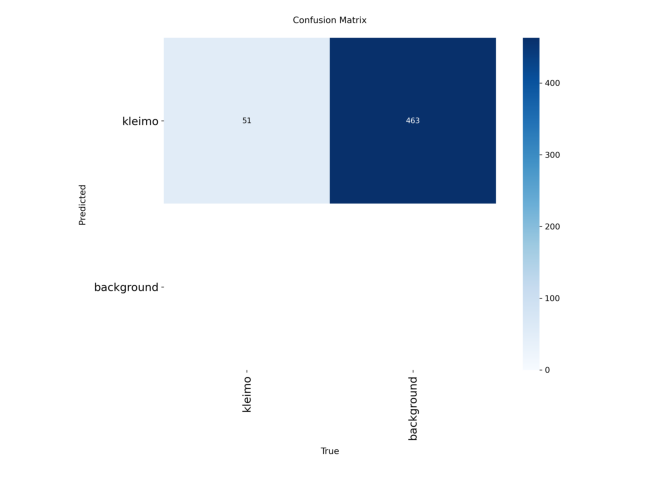

In [3]:
task = Task.init(
    project_name="CeramicNet",
    task_name="misha-yolo26s_with_negatives",
    reuse_last_task_id=False
)

params = {
    "model_name": "yolo26s.pt",
    "data_path": "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic_dataset_yolo/data.yaml",
    "epochs": 50,
    "batch_size": 16,
    "imgsz": 640,
    "optimizer": "auto",
    "close_mosaic": 10,
    "device": 0
}
task.connect(params)

model = YOLO(params["model_name"])

results = model.train(
    data=params["data_path"],
    epochs=params["epochs"],
    batch=params["batch_size"],
    imgsz=params["imgsz"],
    verbose=False,
    optimizer=params["optimizer"],
    close_mosaic=params["close_mosaic"],
    device=params["device"],
    workers=4,
    plots=True
)

task.close()


0: 640x640 (no detections), 11.5ms
1: 640x640 1 kleimo, 11.5ms
2: 640x640 (no detections), 11.5ms
3: 640x640 1 kleimo, 11.5ms
4: 640x640 1 kleimo, 11.5ms
5: 640x640 (no detections), 11.5ms
6: 640x640 (no detections), 11.5ms
7: 640x640 (no detections), 11.5ms
8: 640x640 (no detections), 11.5ms
9: 640x640 1 kleimo, 11.5ms
Speed: 1.4ms preprocess, 11.5ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)


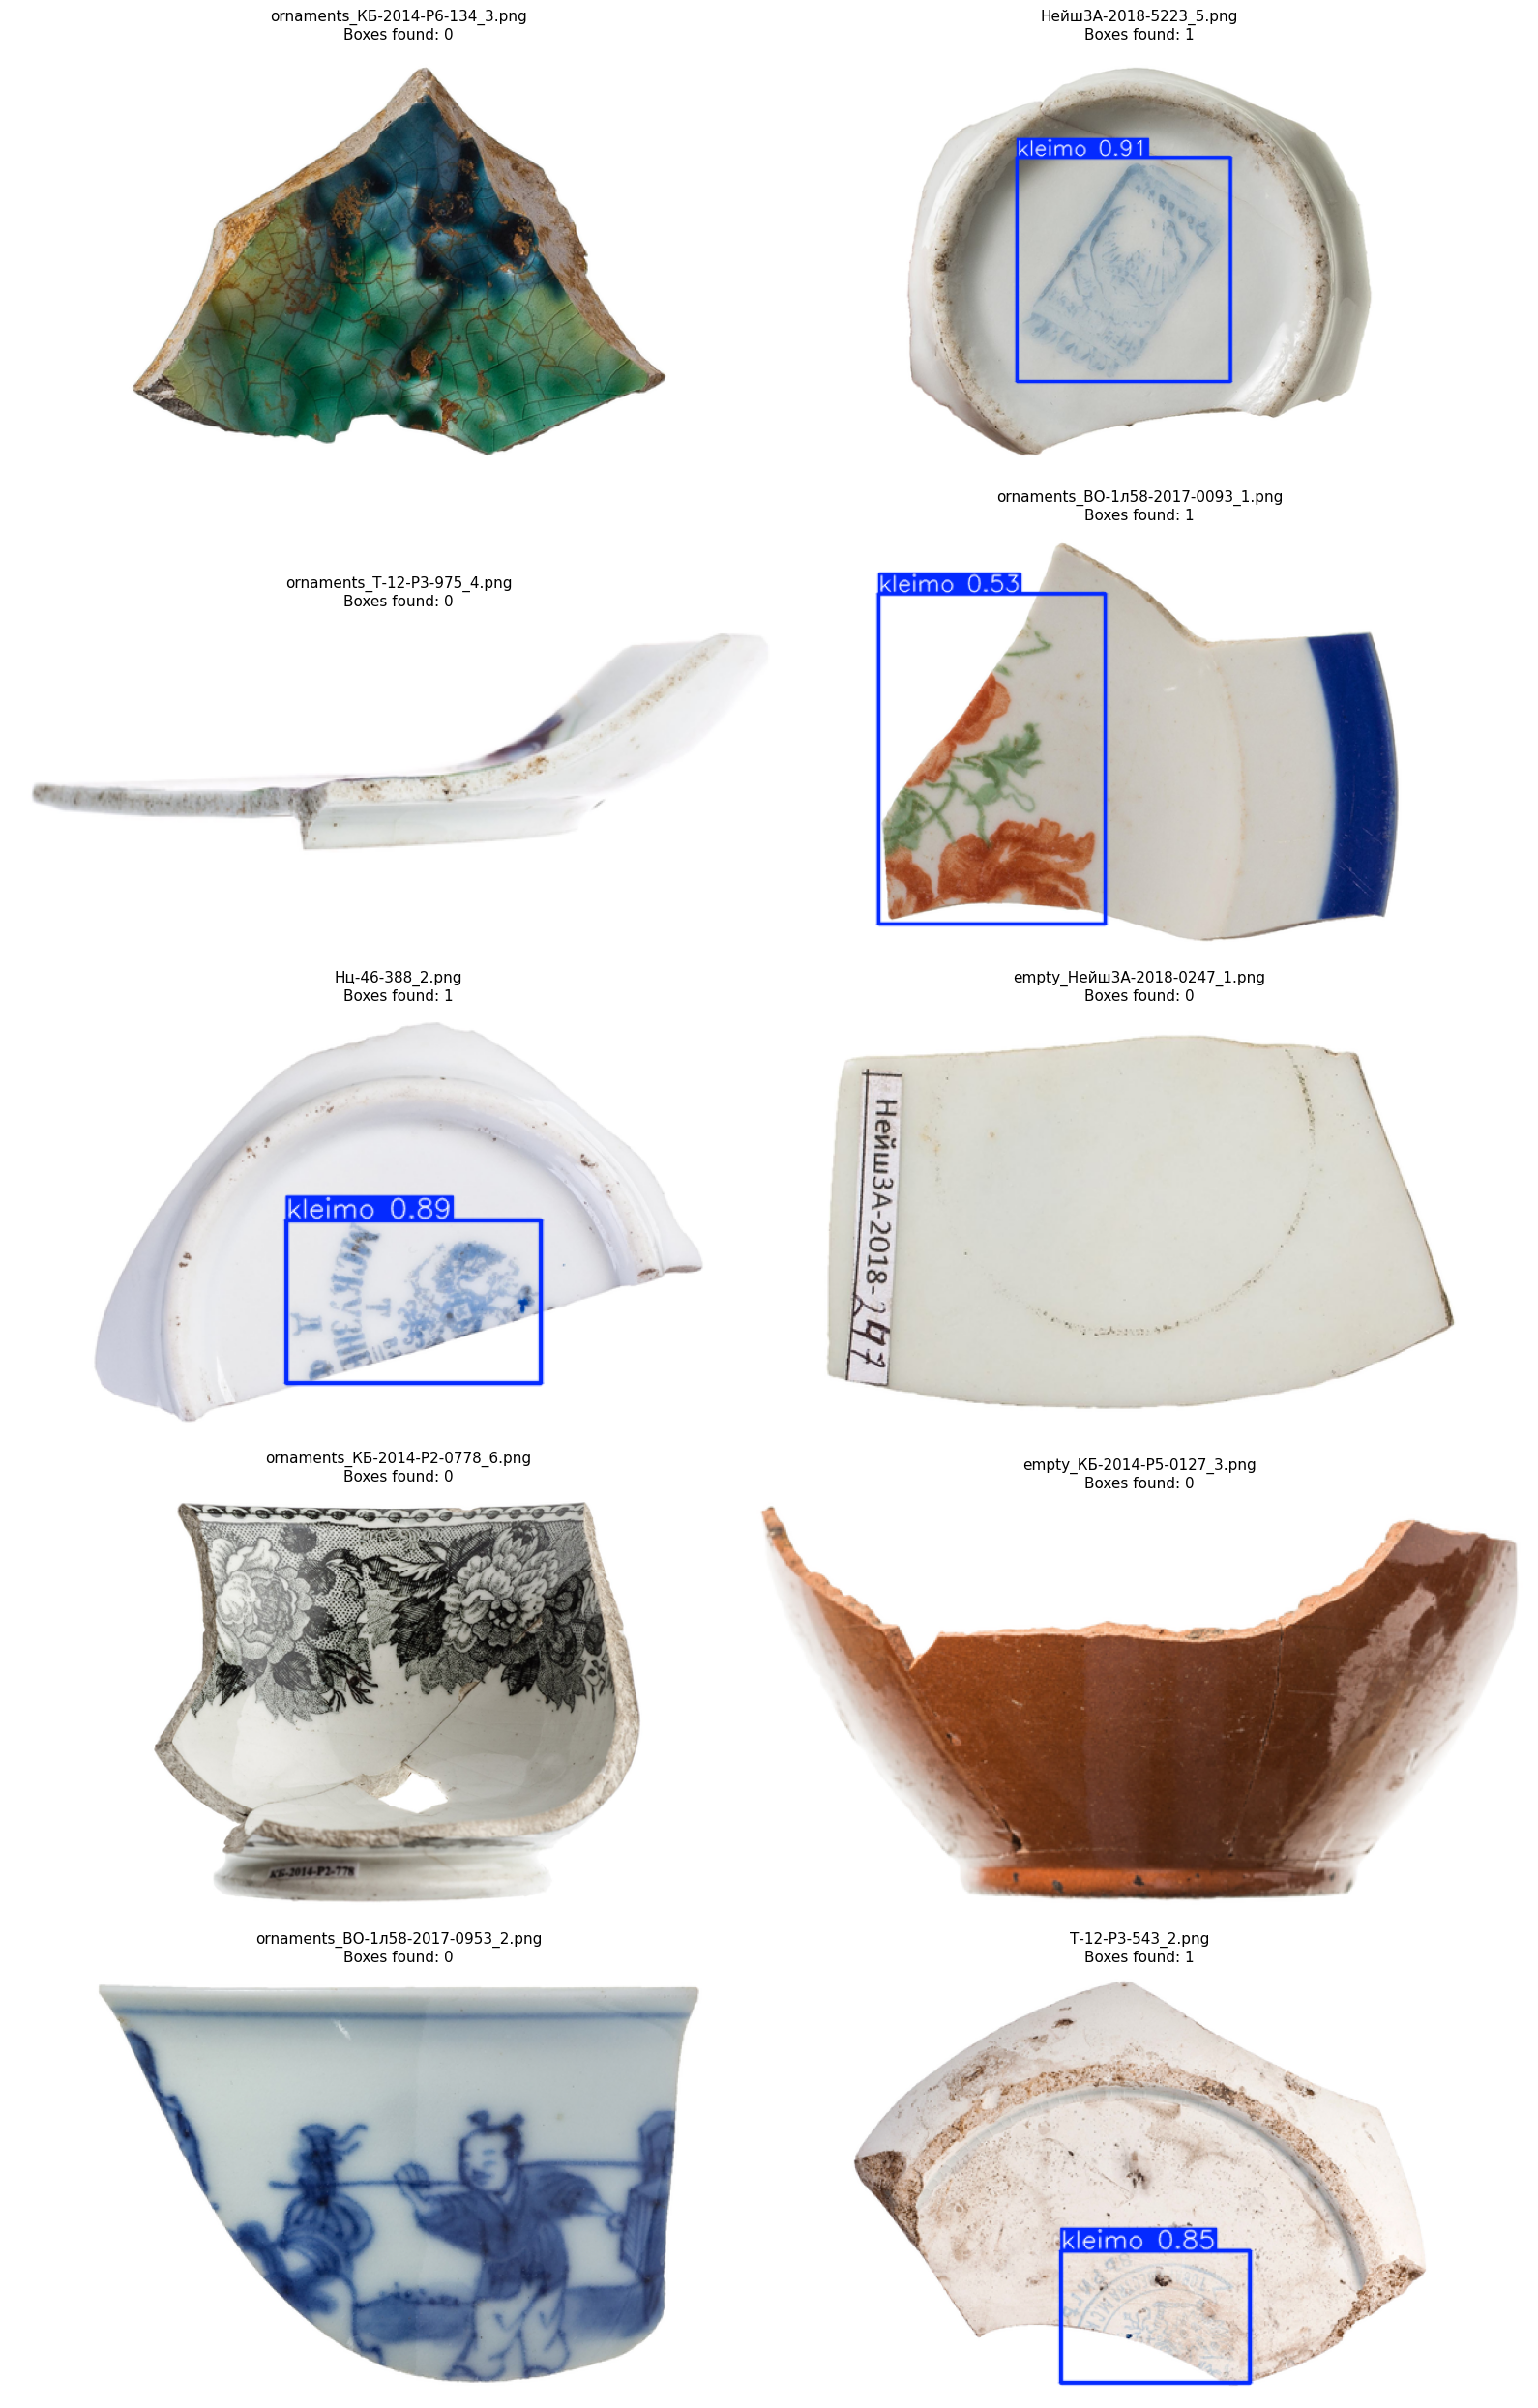

In [5]:
import random
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

val_dir = Path("/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic_dataset_yolo/images/val")
all_val_images = list(val_dir.glob("*.png")) + list(val_dir.glob("*.jpg"))
sample_images = [str(p) for p in random.sample(all_val_images, min(10, len(all_val_images)))]

preds = model.predict(sample_images, conf=0.25, imgsz=640)

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for idx, (img_path, result) in enumerate(zip(sample_images, preds)):
    annotated_img = result.plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(annotated_img_rgb)
    axes[idx].set_title(f"{Path(img_path).name}\nBoxes found: {len(result.boxes)}", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [6]:
import shutil

exported_path = model.export(format="onnx", imgsz=640, dynamic=False)

onnx_path = "/kaggle/working/ceramic_yolo26s.onnx"
shutil.move(exported_path, onnx_path)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train-9/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (19.4 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 488ms
Prepared 2 packages in 2.15s
Installed 2 packages in 11ms
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 3.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 6.2

'/kaggle/working/ceramic_yolo26s.onnx'